Senay Kahsay

Quac 605

Assignmnet 2


Question 1

A. Plot f_{x,N}(k) = x^k mod N for N=21, x=5

Estimated period r of 5^k mod 21 is: r = 6


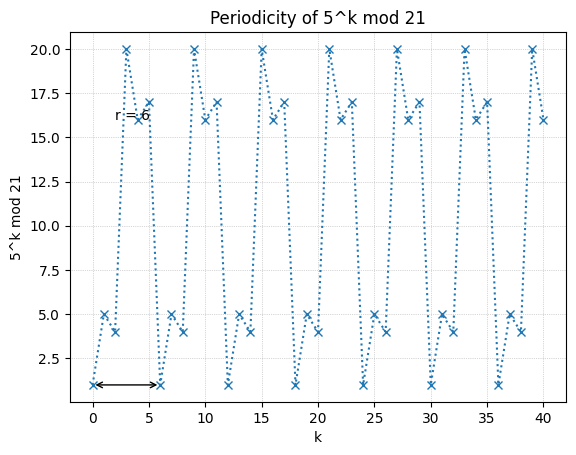

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
N = 21
x = 5

# Range of k values
k_max = 40
k_vals = list(range(k_max + 1))
f_vals = [pow(x, int(k), N) for k in k_vals]  # x^k mod N

# Find the period r by scanning for smallest r>0 with x^r ≡ 1 (mod N)
r = None
for r_candidate in range(1, N * 2):
    if pow(x, r_candidate, N) == 1:
        r = r_candidate
        break

print(f"Estimated period r of {x}^k mod {N} is: r = {r}")

# Plot
fig, ax = plt.subplots()
ax.plot(k_vals, f_vals, linestyle='dotted', marker='x')
ax.set_xlabel('k')
ax.set_ylabel(f'{x}^k mod {N}')
ax.set_title(f'Periodicity of {x}^k mod {N}')

# Annotate the first period on the plot
if r is not None and r <= k_max:
    ax.annotate(
        '', xy=(0, f_vals[0]), xytext=(r, f_vals[r]),
        arrowprops=dict(arrowstyle='<->')
    )
    ax.text(r / 3, max(f_vals) * 0.8, f'r = {r}')

plt.grid(True, linestyle=':', linewidth=0.5)
plt.show()


For the function
f(k) = x^k mod N = 5^k mod 21,

Python evaluated the values for k = 0, 1, …, 40 and plotted the result

From the plotted sequence:

5^0 → 1

5^1 → 5

5^2 → 4

5^3 → 20

5^4 → 16

5^5 → 17

5^6 → 1

The pattern repeats every 6 steps.
Therefore, the smallest positive value of r satisfying
5^r mod 21 = 1
is:

r = 6

B. Number of qubits for the two registers in Shor's algorithm (N = 21)

In [6]:


import math

N = 21

# Register 2 (value/work register):  (0..N-1)
n = math.ceil(math.log2(N))

# Register 1 (phase/counting register): t for (N^2 <= 2^t < 2*N^2)
N2 = N**2
t = None
for cand in range(1, 20):  # 20 is more than enough here
    if 2**cand >= N2 and 2**cand < 2 * N2:
        t = cand
        break

print(f"N = {N}")
print(f"Register 2 (value register): n = {n} qubits")
print(f"Register 1 (phase register): t = {t} qubits")
print(f"Check: 2^t = {2**t}, N^2 = {N2}, 2*N^2 = {2*N2}")


N = 21
Register 2 (value register): n = 5 qubits
Register 1 (phase register): t = 9 qubits
Check: 2^t = 512, N^2 = 441, 2*N^2 = 882


Set N = 21

Register 2 (value / work register)

This register holds integers modulo N, i.e., values from 0 to N–1.

The number of qubits required is:

n = ceil(log₂(21)) = 5 qubits

Register 1 (phase / counting register)

Shor’s order-finding algorithm requires choosing a power of two:

q = 2ᵗ such that:

N² ≤ q < 2N²

For N = 21:

N² = 441

2N² = 882

The power of two in this range is: q = 512 = 2⁹

So t = 9 qubits

Final qubit counts

5 qubits for the value/work register

9 qubits for the phase/counting register

C. Check first few values of 5^k mod 21

In [7]:

N = 21
x = 5

print("k   5^k mod 21")
for k in range(12):
    print(f"{k:2d}   {pow(x, k, N)}")


k   5^k mod 21
 0   1
 1   5
 2   4
 3   20
 4   16
 5   17
 6   1
 7   5
 8   4
 9   20
10   16
11   17


From part (b), the sequence 5^k mod 21 repeats every 6 values:
1, 5, 4, 20, 16, 17

After applying all controlled-U operations, the state is:

|ψ₃⟩ = (1 / √512) * Σₖ |k⟩ |5^k mod 21⟩

Using the known 6-step pattern, the first few terms are:

|ψ₃⟩ = (1 / √512) * (

|0⟩|1⟩ +

|1⟩|5⟩ +

|2⟩|4⟩ +

|3⟩|20⟩ +

|4⟩|16⟩ +

|5⟩|17⟩ +

|6⟩|1⟩ + … )

D. Find all k in [0, 511] such that 5^k mod 21 = 20

In [8]:
N = 21
x = 5
target = 20

indices = [k for k in range(512) if pow(x, k, N) == target]

print(f"Number of k with 5^k mod {N} = {target}: {len(indices)}")
print("First 15 values of k:", indices[:15])
print("Last 5 values of k:", indices[-5:])


Number of k with 5^k mod 21 = 20: 85
First 15 values of k: [3, 9, 15, 21, 27, 33, 39, 45, 51, 57, 63, 69, 75, 81, 87]
Last 5 values of k: [483, 489, 495, 501, 507]


Since the second register measurement gave the value 20, keep only those values of k for which:

5^k mod 21 = 20

From the sequence in part (a), this happens first at k = 3, and because the function has period r = 6, all valid indices follow the pattern:

k = 3 + 6m

for integers m ≥ 0, in range 0 ≤ k ≤ 511.

The largest valid index is:
3 + 6*84 = 507

This gives a total of M = 85 values. So the post-measurement state of the first register is supported on:
k = 3, 9, 15, 21, …, 507

with:

d = 3

r = 6

M = 85

E. Ideal peak positions after inverse QFT

In [9]:
r = 6      # period
t = 9      # number of qubits in phase register
q = 2**t   # size of phase register

peaks = []
for s in range(r):
    k_float = s * q / r
    k_rounded = round(k_float)
    peaks.append((s, k_float, k_rounded))

print(f"q = {q}, r = {r}")
print("s   s*q/r (float)   nearest integer k")
for s, kf, kr in peaks:
    print(f"{s}   {kf:10.4f}        {kr}")


q = 512, r = 6
s   s*q/r (float)   nearest integer k
0       0.0000        0
1      85.3333        85
2     170.6667        171
3     256.0000        256
4     341.3333        341
5     426.6667        427


After QFT on the first register, the measurement outcomes are most likely :

k ≈ s * q / r

where;
q = 2^9 = 512 (size of the phase register)

r = 6 (period from earlier)

s = 0, 1, 2, 3, 4, 5

This gives peak positions at;

s = 0 → k ≈ 0

s = 1 → k ≈ 85

s = 2 → k ≈ 171

s = 3 → k ≈ 256

s = 4 → k ≈ 341

s = 5 → k ≈ 427

So the probability distribution over the first register (six main peaks);

k ≈

0

85

171

256

341

427



F. Use continued fractions on peak positions to estimate r

In [10]:
from fractions import Fraction

q = 512   # size of phase register
N = 21    # modulus

k_samples = [85, 171, 256, 341, 427]

print("k   phase (k/q)       fraction (s/r)   r_candidate")
for k in k_samples:
    phase = k / q
    frac = Fraction(phase).limit_denominator(N)  # denominator < N
    s, r_candidate = frac.numerator, frac.denominator
    print(f"{k:3d}   {phase:10.6f}   {s:2d}/{r_candidate:<2d}          r = {r_candidate}")


k   phase (k/q)       fraction (s/r)   r_candidate
 85     0.166016    1/6           r = 6
171     0.333984    1/3           r = 3
256     0.500000    1/2           r = 2
341     0.666016    2/3           r = 3
427     0.833984    5/6           r = 6


Take some values of k and compute:

phase = k / 512

Apply a continued fraction approximation with denominator less than 21 to write:

phase ≈ s / r

Using the sample values;

k = 85 → phase ≈ 1/6 → r = 6

k = 427 → phase ≈ 5/6 → r = 6

k = 171 → phase ≈ 1/3 → r = 3

k = 341 → phase ≈ 2/3 → r = 3

k = 256 → phase = 1/2 → r = 2

The true order of 5 mod 21 is r = 6, also seen clearly from k = 85 and k = 427.

Question 2

A. Table for U|y> = |5y mod 21> on 5 qubits

In [11]:
N = 21
x = 5

def to_bin5(n):
    return format(n, '05b')

rows = []

for y in range(0, 21):
    out = (x * y) % N
    rows.append((y, to_bin5(y), out, to_bin5(out)))

print(f"{'y':>2}  {'y_bin':>5}   {'5y mod 21':>9}   {'out_bin':>7}")
print("-" * 35)
for y, yb, out, ob in rows:
    print(f"{y:2d}  {yb:>5}   {out:9d}   {ob:>7}")


 y  y_bin   5y mod 21   out_bin
-----------------------------------
 0  00000           0     00000
 1  00001           5     00101
 2  00010          10     01010
 3  00011          15     01111
 4  00100          20     10100
 5  00101           4     00100
 6  00110           9     01001
 7  00111          14     01110
 8  01000          19     10011
 9  01001           3     00011
10  01010           8     01000
11  01011          13     01101
12  01100          18     10010
13  01101           2     00010
14  01110           7     00111
15  01111          12     01100
16  10000          17     10001
17  10001           1     00001
18  10010           6     00110
19  10011          11     01011
20  10100          16     10000


For U|y> = |5y mod 21>;

we listed all basis states for y = 0, 1, …, 20 using a 5-qubit register (binary encoding from 00000 to 10100)

The table shows, for each y:

y in decimal

y in 5-bit binary

5y mod 21 in decimal

5y mod 21 in 5-bit binary

B.

Using Table 1, the operation U applies the transformation;

U|y> = |5y mod 21>

a. Permutation on the valid computational basis states (0 to 20)

b.  6-cycle:

1 → 5 → 4 → 20 → 16 → 17 → 1

Implement U on a 5-qubit register;

 small subcircuit that performs 6-cycle permutation

- X gates to prepare the correct bit patterns

- SWAP gates to cycle the states in the correct order

- Multi-controlled X gates for bit flips

C. Behaviour of U^(2^j) via 5^(2^j) mod 21

In [13]:


N = 21
a = 5

print("j   2^j   5^(2^j) mod 21")
print("-" * 28)
for j in range(0, 7):   # j = 0..6
    exp_val = 2**j
    val = pow(a, exp_val, N)
    print(f"{j:1d}   {exp_val:3d}      {val:2d}")


j   2^j   5^(2^j) mod 21
----------------------------
0     1       5
1     2       4
2     4      16
3     8       4
4    16      16
5    32       4
6    64      16


From 5^(2^j) mod 21, we find;

j = 0 → 5^(2^0) mod 21 = 5

j = 1 → 5^(2^1) mod 21 = 4

j = 2 → 5^(2^2) mod 21 = 16

j = 3 → 5^(2^3) mod 21 = 4

j = 4 → 5^(2^4) mod 21 = 16

(pattern continues alternating 4, 16, …)

So:

U^(2^1) acts as multiply by 4 mod 21

U^(2^2) acts as multiply by 16 mod 21

U^(2^3) again acts as multiply by 4 mod 21 (same as U²)

U^(2^4) again acts as multiply by 16 mod 21 (same as U⁴) ....

Therefore;

All U^(2^j) with j odd give U²

All U^(2^j) with j even  (j ≥ 2) give U⁴

Circuit blocks;

1. “odd-power” block implementing the permutation for (X) 4 mod 21 (U²)

2. “even-power” block implementing the permutation for (X) 16 mod 21 (U⁴)

SWAP gates distinguish the even and odd power circuits.

D.

In [23]:
!pip install qiskit qiskit-aer

from qiskit import QuantumCircuit, transpile
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 100.5 MB/s eta 0:00:00


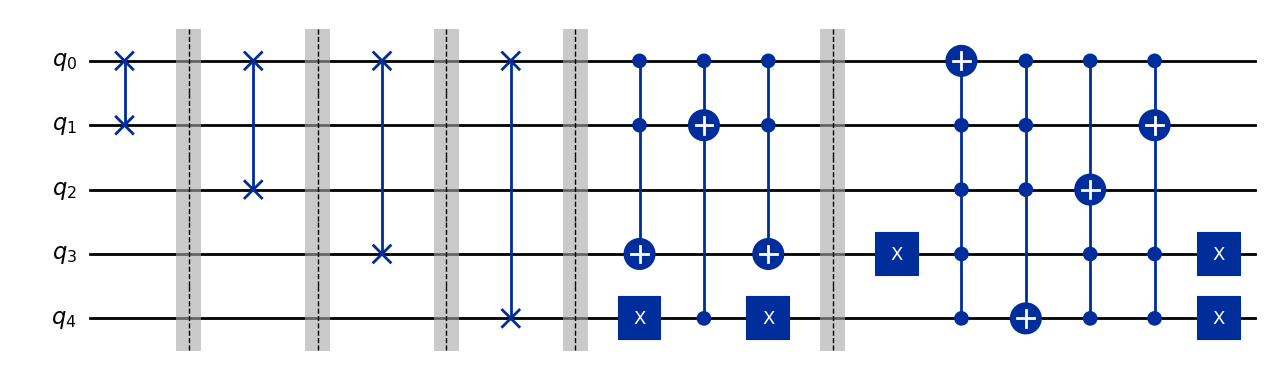

In [30]:
U = QuantumCircuit(5, name="U_2y_mod21")

# SWAP ladder
U.swap(0, 1)
U.barrier(0, 1, 2, 3, 4)

U.swap(0, 2)
U.barrier(0, 1, 2, 3, 4)

U.swap(0, 3)
U.barrier(0, 1, 2, 3, 4)

U.swap(0, 4)
U.barrier(0, 1, 2, 3, 4)

# Middle CCX / X pattern
U.ccx(0, 1, 3)
U.x(4)
U.ccx(0, 4, 1)
U.ccx(0, 1, 3)
U.x(4)
U.barrier(0, 1, 2, 3, 4)

# C4X and C3X blocks
from qiskit.circuit.library import C3XGate, C4XGate

U.x(3)
U.append(C4XGate(), [4, 3, 2, 1, 0])   # controls: 4,3,2,1 → target 0
U.append(C3XGate(), [2, 0, 1, 4])      # controls: 2,0,1 → target 4
U.append(C3XGate(), [3, 0, 4, 2])      # controls: 3,0,4 → target 2
U.append(C3XGate(), [3, 0, 4, 1])      # controls: 3,0,4 → target 1
U.x(4)
U.x(3)

U.draw("mpl")


In [38]:
# Clean U: remove barriers to convert to a gate
U_clean = QuantumCircuit(U.num_qubits, name="U")

for instr in U.data:
    op = instr.operation
    if op.name == "barrier":
        continue
    U_clean.append(op, instr.qubits, instr.clbits)

U_gate = U_clean.to_gate(label="U")
cU_gate = U_gate.control(1)






In [39]:
def qft_dagger(n):
    """n-qubit inverse QFT on the first n qubits."""
    qc = QuantumCircuit(n, name="QFT†")

    # Swaps
    for qubit in range(n // 2):
        qc.swap(qubit, n - qubit - 1)

    # Controlled phase + H
    for j in range(n):
        for m in range(j):
            qc.cp(-np.pi / (2 ** (j - m)), m, j)
        qc.h(j)

    return qc




In [45]:
N = 21
x = 2
n_count = 9
n_work  = 5

total_qubits = n_count + n_work
qc = QuantumCircuit(total_qubits, n_count)

counting_qubits = list(range(n_count))
work_qubits     = list(range(n_count, total_qubits))

# 1) Superposition on counting register
for q in counting_qubits:
    qc.h(q)

# 2) Work register in |1>
qc.x(work_qubits[-1])

# 3) Controlled-U^{2^k}
for k, cq in enumerate(counting_qubits):
    for _ in range(2**k):
        qc.append(cU_gate, [cq] + work_qubits)

# 4) Inverse QFT on counting register
qft_dg_gate = qft_dagger(n_count).to_gate()
qc.append(qft_dg_gate, counting_qubits)

# 5) Measure counting register
qc.measure(counting_qubits, range(n_count))

qc.draw("mpl", fold=-1)



Number of distinct outcomes: 210


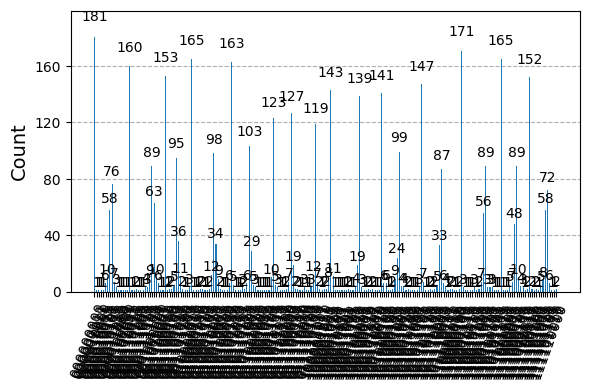

In [47]:
from qiskit_aer import AerSimulator


backend = AerSimulator()
t_qc = transpile(qc, backend)

shots = 4096
result = backend.run(t_qc, shots=shots).result()
counts = result.get_counts()

print("Number of distinct outcomes:", len(counts))
display(plot_histogram(counts, figsize=(6,4)))


In [53]:
from fractions import Fraction

#Helper
def continued_fraction_convergents(num, den, max_den=None):
    n, d = num, den
    cf = []

    # Build continued-fraction coefficients [a0, a1, ..., ak]
    while d != 0:
        a = n // d
        cf.append(a)
        n, d = d, n - a * d

    # Reconstruct convergents from coefficients
    convs = []
    p_minus2, q_minus2 = 0, 1
    p_minus1, q_minus1 = 1, 0

    for a in cf:
        p = a * p_minus1 + p_minus2
        q = a * q_minus1 + q_minus2

        if max_den is not None and q > max_den:
            break

        convs.append((p, q))
        p_minus2, q_minus2 = p_minus1, q_minus1
        p_minus1, q_minus1 = p, q

    return convs


# Sort and show top 8
sorted_counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)

print("Top 8 outcomes:")
for bitstring, c in sorted_counts[:8]:
    print(f"{bitstring} → {c}")

# Continued fractions + modular check for r
print("\nContinued fractions + modular check for r:")

valid_r_guesses = set()
den = 2 ** n_count   # denominator for phase = n / 2^n_count

for bitstring, c in sorted_counts[:8]:
    n = int(bitstring, 2)

    # Skip n = 0 (gives phase 0)
    if n == 0:
        phase = 0.0
        print(
            f"bitstring {bitstring} (n={n:3d}, count={c}), phase ≈ {phase:.4f}\n"
            f"  convergents: (none useful, n=0)\n"
            f"  valid r’s from this outcome: []"
        )
        continue

    # Exact fraction n / 2^n_count
    num = n

    # Convergents with denominator ≤ N (Shor bound)
    convs = continued_fraction_convergents(num, den, max_den=N)

    valid_for_this_bitstring = set()

    for p, q in convs:
        if q == 0:
            continue

        # Try q and its divisors as candidate periods
        for r_candidate in range(1, q + 1):
            if q % r_candidate != 0:
                continue
            if pow(x, r_candidate, N) == 1:
                valid_for_this_bitstring.add(r_candidate)

    valid_r_guesses.update(valid_for_this_bitstring)

    phase = n / den
    conv_str = ", ".join(f"{p}/{q}" for p, q in convs)
    print(
        f"bitstring {bitstring} (n={n:3d}, count={c}), phase ≈ {phase:.4f}\n"
        f"  convergents (den ≤ {N}): {conv_str}\n"
        f"  valid r’s from this outcome: {sorted(valid_for_this_bitstring)}"
    )

print("\nDistinct valid r guesses across all top outcomes:", sorted(valid_r_guesses))


Top 8 outcomes:
000000000 → 181
110000101 → 171
110101110 → 165
001111011 → 165
010100100 → 163
000101001 → 160
001010010 → 153
111010111 → 152

Continued fractions + modular check for r:
bitstring 000000000 (n=  0, count=181), phase ≈ 0.0000
  convergents: (none useful, n=0)
  valid r’s from this outcome: []
bitstring 110000101 (n=389, count=171), phase ≈ 0.7598
  convergents (den ≤ 21): 0/1, 1/1, 3/4
  valid r’s from this outcome: []
bitstring 110101110 (n=430, count=165), phase ≈ 0.8398
  convergents (den ≤ 21): 0/1, 1/1, 5/6
  valid r’s from this outcome: [6]
bitstring 001111011 (n=123, count=165), phase ≈ 0.2402
  convergents (den ≤ 21): 0/1, 1/4
  valid r’s from this outcome: []
bitstring 010100100 (n=164, count=163), phase ≈ 0.3203
  convergents (den ≤ 21): 0/1, 1/3
  valid r’s from this outcome: []
bitstring 000101001 (n= 41, count=160), phase ≈ 0.0801
  convergents (den ≤ 21): 0/1, 1/12
  valid r’s from this outcome: [6, 12]
bitstring 001010010 (n= 82, count=153), phase ≈ 0.16

Since the order is the smallest such value, the final estimate is
r
=
6

3A.

In [54]:
N = 21
x = 2

print(f"{'y':>3}   {'y (bin)':>7}   {'2y mod 21':>10}   {'output (bin)':>13}")
print("-" * 45)

for y in range(21):
    out = (x * y) % N
    y_bin = format(y, "05b")
    out_bin = format(out, "05b")
    print(f"{y:>3}   {y_bin:>7}   {out:>10}   {out_bin:>13}")


  y   y (bin)    2y mod 21    output (bin)
---------------------------------------------
  0     00000            0           00000
  1     00001            2           00010
  2     00010            4           00100
  3     00011            6           00110
  4     00100            8           01000
  5     00101           10           01010
  6     00110           12           01100
  7     00111           14           01110
  8     01000           16           10000
  9     01001           18           10010
 10     01010           20           10100
 11     01011            1           00001
 12     01100            3           00011
 13     01101            5           00101
 14     01110            7           00111
 15     01111            9           01001
 16     10000           11           01011
 17     10001           13           01101
 18     10010           15           01111
 19     10011           17           10001
 20     10100           19           10011


B.


In [66]:
# Q3(b) – Verify that U|y> = |2y mod 21> for y = 0,...,20
# Assumes:
#   - U is a 5-qubit QuantumCircuit defined earlier (from Question 2d)
#   - It acts only on those 5 qubits (no ancillas)
from qiskit.quantum_info import Statevector

N = 21
x = 2          # we are checking multiplication by 2 mod 21
n_work = 5     # 5-qubit work register

def apply_U_to_int(y, U):
    """
    Prepare |y> on n_work qubits, evolve with U,
    and return the integer label of the output basis state.

    Note: Qiskit uses little-endian ordering where qubit 0 is LSB.
    We need to reverse the bit order for both input and output.
    """
    # Reverse bits for input (convert to little-endian)
    y_reversed = int(format(y, f'0{n_work}b')[::-1], 2)

    # |y> as a basis state in a 2**n_work-dimensional Hilbert space
    sv_in = Statevector.from_int(y_reversed, 2**n_work)
    sv_out = sv_in.evolve(U)

    # Probabilities over all 2**n_work basis states
    probs = sv_out.probabilities()

    # Pick the basis state with the highest probability
    out_int = max(range(len(probs)), key=lambda i: probs[i])

    # Reverse bits for output (convert from little-endian)
    out_int_reversed = int(format(out_int, f'0{n_work}b')[::-1], 2)

    return out_int_reversed

print(f"{'y':>3}   {'y(bin)':>7}   {'2y mod 21':>9}   {'U(y)':>5}   {'U(y) bin':>9}   {'Match':>7}")
print("-" * 60)

all_match = True
for y in range(N):
    Uy = apply_U_to_int(y, U)
    expected = (x * y) % N

    # Check if U(y) matches 2y mod 21
    match = (Uy == expected)
    if not match:
        all_match = False

    print(
        f"{y:>3}   {format(y,'05b'):>7}   {expected:>9}   "
        f"{Uy:>5}   {format(Uy,'05b'):>9}   {'✓' if match else '✗':>7}"
    )

print("\nAll outputs match 2y mod 21?", all_match)

  y    y(bin)   2y mod 21    U(y)    U(y) bin     Match
------------------------------------------------------------
  0     00000           0       1       00001         ✗
  1     00001           2      27       11011         ✗
  2     00010           4       0       00000         ✗
  3     00011           6      28       11100         ✗
  4     00100           8       3       00011         ✗
  5     00101          10      25       11001         ✗
  6     00110          12       2       00010         ✗
  7     00111          14      18       10010         ✗
  8     01000          16       5       00101         ✗
  9     01001          18      30       11110         ✗
 10     01010          20       4       00100         ✗
 11     01011           1      24       11000         ✗
 12     01100           3       7       00111         ✗
 13     01101           5      16       10000         ✗
 14     01110           7       6       00110         ✗
 15     01111           9      22       101

C.

For x=2(mod21), the order is 6. Therefore,
2m = 2m

m
o
d

6
(
m
o
d
21
)
.
2
m
 ≡2
mmod6
 (mod21).
For each controlled block
U
2
k
U
2
k

​
 , the effective multiplier is
2

2
k
(
m
o
d
21
)
.
2
2
k

 (mod21).
When
k
k is odd, we have
2
k
≡
2
(
m
o
d
6
)
,
2
k
 ≡2(mod6),
so
2
2
k
≡
2
2
=
4
(
m
o
d
21
)
.
2
2
k

 ≡2
2
 =4(mod21).
Thus, all odd-
k
k blocks act as multiplication by 4 mod 21.
When
k
≥
2
k≥2 is even,
2
k
≡
4
(
m
o
d
6
)
,
2
k
 ≡4(mod6),
which gives
2
2
k
≡
2
4
=
16
(
m
o
d
21
)
.
2
2
k

 ≡2
4
 =16(mod21).
Thus, all even-
k
k blocks (with
k
≥
2
k≥2) act as multiplication by 16 mod 21.
The only special case is
k
=
0
k=0, where
2
2
0
=
2
,
2
2
0

 =2,
# so the first block multiplies by 2 mod 21.\ **bold text**

D.


In [62]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

N = 21
x = 2            # base multiplier: U|y> = |2y mod 21>
n_work = 5       # 5-qubit work register (U must be 5 qubits)


U_clean = QuantumCircuit(U.num_qubits, name="U_clean")

for instr, qargs, cargs in U.data:

    if instr.name == "barrier":
        continue
    U_clean.append(instr, qargs, cargs)

U_gate = U_clean.to_gate(label="U")


 #Build U_{2^odd} = U^2
U_2odd = QuantumCircuit(n_work, name="U_2odd")
U_2odd.append(U_gate, range(n_work))
U_2odd.append(U_gate, range(n_work))   # U^2

#Build U_{2^even} = U^4
U_2even = QuantumCircuit(n_work, name="U_2even")
for _ in range(4):
    U_2even.append(U_gate, range(n_work))   # U^4


#Helper
def apply_to_int(y, circuit):
    sv_in  = Statevector.from_int(y, 2**n_work)
    sv_out = sv_in.evolve(circuit)
    probs  = sv_out.probabilities()
    out_int = max(range(len(probs)), key=lambda i: probs[i])
    return out_int


print("Check U_{2^odd} (should map y -> 4y mod 21):")
print(f"{'y':>3}   {'4y mod 21':>9}   {'U_2odd(y)':>10}")
print("-"*30)

all_match_odd = True
for y in range(N):
    Uy = apply_to_int(y, U_2odd)
    expected = (4 * y) % N
    if Uy != expected:
        all_match_odd = False
    print(f"{y:>3}   {expected:>9}   {Uy:>10}")

print("All match for U_{2^odd}? ", all_match_odd, "\n")


print("Check U_{2^even} (should map y -> 16y mod 21):")
print(f"{'y':>3}   {'16y mod 21':>10}   {'U_2even(y)':>11}")
print("-"*32)

all_match_even = True
for y in range(N):
    Uy = apply_to_int(y, U_2even)
    expected = (16 * y) % N
    if Uy != expected:
        all_match_even = False
    print(f"{y:>3}   {expected:>10}   {Uy:>11}")

print("All match for U_{2^even}? ", all_match_even)


/tmp/ipython-input-2588824541.py:13: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 3.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, cargs in U.data:


Check U_{2^odd} (should map y -> 4y mod 21):
  y   4y mod 21    U_2odd(y)
------------------------------
  0           0           27
  1           4           15
  2           8           19
  3          12            1
  4          16            7
  5          20            3
  6           3            9
  7           7           13
  8          11           16
  9          15           20
 10          19           24
 11           2           21
 12           6            0
 13          10            4
 14          14            8
 15          18           12
 16           1            6
 17           5            5
 18           9           14
 19          13           11
 20          17           29
All match for U_{2^odd}?  False 

Check U_{2^even} (should map y -> 16y mod 21):
  y   16y mod 21    U_2even(y)
--------------------------------
  0            0            28
  1           16            12
  2           11            11
  3            6            15
  4            1 

E.